In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [6]:
data=pd.read_csv('Solid_Waste_Generation_Recycling.csv')
df1=data # save original data as backup 

In [7]:
data

,Year,Agricultural Organics,Aluminum Cans,Anti-freeze,Appliances/White Goods,"Ash, Sand & Dust used in Asphalt Production",Asphalt/Concrete,Batteries - Auto Lead Acid,Cardboard,Carpet & Pad,...,Waste Types Excluded from Recovery Rate,All Other Waste Types,Total Solid Waste Disposed (recoverable portion),All Solid Waste Disposal,Solid Waste Generated (recoverable portion),Overall Waste Generated (recoverable and non-recoverable),Material Recovery Rate,Population,Solid Waste Generated (pounds/person/day),Material Reovered (pounds/person/day)
0,2000,0,17944,2475,35427,10000,893218,10757,495470,97,...,549239.00,2515427.00,6.577102e+06,7126341,10463584,11012823,37.14,5894100,10.238075,3.613069
1,2001,0,12540,4157,39180,12333,1116871,16297,491230,820,...,1192376.00,2838771.00,6.257801e+06,7450177,10524608,11716984,40.54,5974900,10.745394,3.912997
2,2002,0,12718,4506,43833,290,1451959,12158,417534,148,...,1343941.00,2724337.00,6.084275e+06,7428216,10998676,12342617,44.68,6041700,11.193998,4.457061
3,2003,0,17608,4722,53353,10576,1600288,18780,430750,258,...,1350013.00,2666863.00,6.122052e+06,7472065,11353874,12703887,46.08,6098300,11.414713,4.700903
4,2004,0,16010,8050,56920,40409,2002171,25518,535662,304,...,2557428.00,4153915.00,6.526087e+06,9083515,12760061,15317489,48.86,6167800,13.608004,5.538241
5,2005,0,15441,8767,47302,14588,1783418,28903,565698,186,...,2736151.00,5355491.00,7.696424e+06,10432575,14758169,17494320,47.85,6256400,15.321797,6.184786
6,2006,0,14951,7507,49796,4008,2295278,25414,570802,897,...,1689840.00,4164837.00,7.760714e+06,9450554,15442903,17132743,49.75,6375600,14.724582,6.602388
7,2007,0,14005,7055,44667,2521,2089972,25734,555757,1193,...,1810580.00,4557764.00,8.082291e+06,9892871,15372234,17182814,47.42,6488000,14.511776,6.156734
8,2008,31800,12842,6586,43401,0,1510051,25219,569688,3297,...,1634267.82,4154879.40,7.516909e+06,9151177,14309506,15943774,47.47,6587600,13.261756,5.649965
9,2009,45431,21098,5194,39777,344,2186429,21493,491266,3317,...,1550645.32,3039032.92,6.126660e+06,7677305,13564327,15114972,54.83,6668200,12.420408,6.111746


In [8]:
data.shape

(15, 80)

In [9]:
df=data.sort_values('Aluminum Cans')# SORTED

In [11]:
#display the first 5 and last 5 rows
df['Aluminum Cans'].head()

1     12540
2     12718
8     12842
11    13115
12    13635
Name: Aluminum Cans, dtype: int64

In [12]:
df['Aluminum Cans'].tail()

4     16010
13    16679
3     17608
0     17944
9     21098
Name: Aluminum Cans, dtype: int64

In [13]:
# If we observe the difference b/w the last row and previous row its 
#21098-17944= 3154 this is abnormal

In [14]:
# we need to apply box plot to find outlier

<Axes: xlabel='Aluminum Cans'>

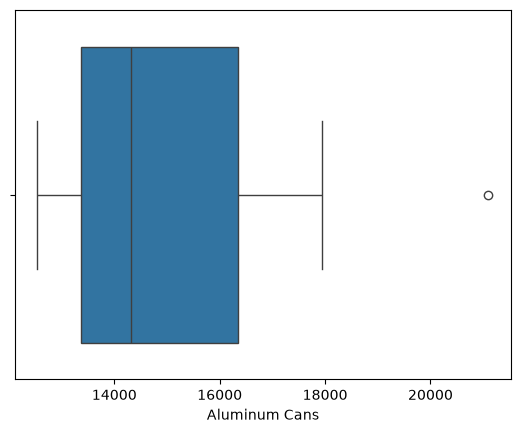

In [15]:
sns.boxplot(data=data,x='Aluminum Cans')

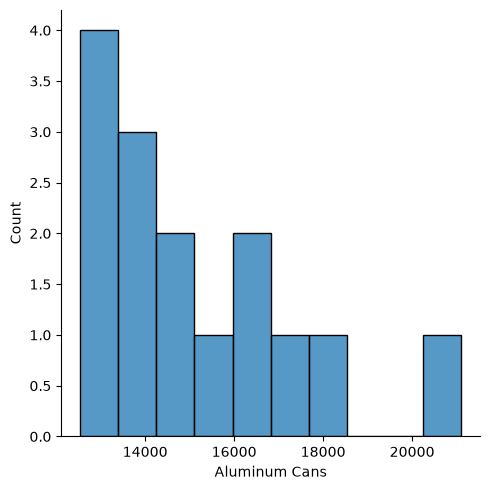

In [16]:
sns.displot(data=data,x='Aluminum Cans',bins=10)

#IQR METHOD
IQR represents the range of values b/w 75th and 25th percentiles,
we can divide the total data in 4 parts or 4 percentiles as:-
Q1 25th percentile
Q2 50th percentile
Q3 75th percentile
Q4 100th percentile

IQR=Q3-Q1

PYTHON OFFERS THE METHOD quantile() to calculate percentiles.



In [18]:
q3=data['Aluminum Cans'].quantile(0.75)

In [20]:
print(q3)

16344.5


In [21]:
q1=data['Aluminum Cans'].quantile(0.25)
print(q1)

13375.0


In [22]:
iqr=q3-q1

In [24]:
print(iqr)

2969.5


In [25]:
# The iqr value helps us to find the valid upper and valid lower limit in the dataset.
#valid upper :-   ul=q3 + (1.5 * iqr)
#valid lower :-   ll=q1 - (1.5 * iqr)
ul=q3 + (1.5 * iqr)

In [27]:
print(ul)

20798.75


In [28]:
ll=q1 - (1.5 * iqr)
print(ll)

8920.75


In [29]:
print(f"the upper valid is {ul} and lower valid is {ll}")

the upper valid is 20798.75 and lower valid is 8920.75


ANY VALUE ABOVE 20798.75 WILL BE OUTLIER
ANY VALUE LOWER THAN 8920.75 WILL BE OULIER
IN OUR DATASET WE HAVE THE 10TH ROW HAVING 21098 WHICH IS > THAN 20798.75 HENCE AN OUTLIER

HOW TO HANDLE OUTLIER?

EITHER DELETE IT OR REPLACE IT.
IF THE DATASET CONTAINS HUGE NO OF ROWS THEN IT IS BETTER TO DELETE THEM
BUT FOR LESS NO OF ROWS BETTER REPLACE OUTLIER WITH AVERAGE VALUES

In [30]:
# HOW TO DELETE ?

In [31]:
# to find the upper bound above ul

In [32]:
upper=np.where(data['Aluminum Cans'] >= ul)

In [33]:
# to find the lower bound below ll
lower=np.where(data['Aluminum Cans'] <= ll)

In [34]:
print(upper)

(array([9]),)


In [35]:
print(lower)

(array([], dtype=int64),)


In [36]:
data.drop(upper[0],inplace=True)
data.drop(lower[0],inplace=True)


In [37]:
data

,Year,Agricultural Organics,Aluminum Cans,Anti-freeze,Appliances/White Goods,"Ash, Sand & Dust used in Asphalt Production",Asphalt/Concrete,Batteries - Auto Lead Acid,Cardboard,Carpet & Pad,...,Waste Types Excluded from Recovery Rate,All Other Waste Types,Total Solid Waste Disposed (recoverable portion),All Solid Waste Disposal,Solid Waste Generated (recoverable portion),Overall Waste Generated (recoverable and non-recoverable),Material Recovery Rate,Population,Solid Waste Generated (pounds/person/day),Material Reovered (pounds/person/day)
0,2000,0,17944,2475,35427,10000,893218,10757,495470,97,...,549239.00,2515427.00,6.577102e+06,7126341,10463584,11012823,37.14,5894100,10.238075,3.613069
1,2001,0,12540,4157,39180,12333,1116871,16297,491230,820,...,1192376.00,2838771.00,6.257801e+06,7450177,10524608,11716984,40.54,5974900,10.745394,3.912997
2,2002,0,12718,4506,43833,290,1451959,12158,417534,148,...,1343941.00,2724337.00,6.084275e+06,7428216,10998676,12342617,44.68,6041700,11.193998,4.457061
3,2003,0,17608,4722,53353,10576,1600288,18780,430750,258,...,1350013.00,2666863.00,6.122052e+06,7472065,11353874,12703887,46.08,6098300,11.414713,4.700903
4,2004,0,16010,8050,56920,40409,2002171,25518,535662,304,...,2557428.00,4153915.00,6.526087e+06,9083515,12760061,15317489,48.86,6167800,13.608004,5.538241
5,2005,0,15441,8767,47302,14588,1783418,28903,565698,186,...,2736151.00,5355491.00,7.696424e+06,10432575,14758169,17494320,47.85,6256400,15.321797,6.184786
6,2006,0,14951,7507,49796,4008,2295278,25414,570802,897,...,1689840.00,4164837.00,7.760714e+06,9450554,15442903,17132743,49.75,6375600,14.724582,6.602388
7,2007,0,14005,7055,44667,2521,2089972,25734,555757,1193,...,1810580.00,4557764.00,8.082291e+06,9892871,15372234,17182814,47.42,6488000,14.511776,6.156734
8,2008,31800,12842,6586,43401,0,1510051,25219,569688,3297,...,1634267.82,4154879.40,7.516909e+06,9151177,14309506,15943774,47.47,6587600,13.261756,5.649965
10,2010,55689,13655,4783,48881,20364,2188200,26986,471477,3867,...,1229535.00,3703149.00,7.043048e+06,8272583,15261820,16491355,53.85,6724540,13.437884,6.697018


In [38]:
# for less no of rows replace outliers with resonable values
# generally its done by mean/mediun values
arr=data['Aluminum Cans'].values


In [39]:
arr

array([17944, 12540, 12718, 17608, 16010, 15441, 14951, 14005, 12842,
       13655, 13115, 13635, 16679, 14309])

In [40]:
true_index=(ll<arr) & (arr<ul)

In [41]:
true_index

array([ True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True])

In [42]:
mid=np.median(data['Aluminum Cans'][true_index])
print(mid)

14157.0
